<a href="https://colab.research.google.com/github/pradyumn980/EV-Battery-Anomaly-Detection/blob/main/EV_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd

# List files in the current workspace to find the uploaded dataset
files = [f for f in os.listdir('.') if os.path.isfile(f)]
print('Files in current directory:', files)

# Attempt to auto-detect and load the first CSV or Excel file
data_file = None
for f in files:
    if f.endswith('.csv') or f.endswith('.xlsx') or f.endswith('.xls'):
        data_file = f
        break

if data_file:
    print(f'Loading dataset: {data_file}')
    if data_file.endswith('.csv'):
        df = pd.read_csv(data_file)
    else:
        df = pd.read_excel(data_file)
    display(df.head())
    display(df.info())
else:
    print('No CSV or Excel dataset detected. Please upload your dataset to the Colab environment or specify its path.')

Files in current directory: ['ev_battery_health.csv']
Loading dataset: ev_battery_health.csv


,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  object 
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_charging_power_kw           

None

In [ ]:
data = df.copy()

print("Original shape:", data.shape)

Original shape: (50000, 35)


In [ ]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [ ]:
missing = data.isnull().sum()

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage': (missing / len(data)) * 100
})

display(missing_df[missing_df['Missing Count'] > 0]
        .sort_values('Missing Percentage', ascending=False))

,Missing Count,Missing Percentage
last_service_date,18831,37.662
vehicle_model,3515,7.030
chemistry,3459,6.918
fast_charge_ratio,3405,6.810
total_energy_throughput_kwh,3370,6.740
avg_ambient_temp_c,3282,6.564
avg_state_of_charge_pct,3138,6.276
battery_age_days,3002,6.004
avg_depth_of_discharge_pct,2832,5.664
voltage_avg_v,2807,5.614


In [ ]:
sensor_features = [
    'internal_resistance_mohm',
    'peak_temp_during_fast_charge_c',
    'charge_time_avg_min'
]

data = data.dropna(subset=sensor_features, how='all')

print("Shape:", data.shape)

Shape: (49997, 35)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    data[sensor_features]
)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (49997, 3)


In [ ]:
processed_data = pd.DataFrame(
    X_scaled,
    columns=sensor_features,
    index=data.index
)

display(processed_data.head())

print("\nMissing values:")
print(processed_data.isnull().sum())

print("\nStatistical summary:")
display(processed_data.describe())


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
0,2.040741,-2.162440,-0.790161
1,0.034756,-1.651400,-0.809451
2,-0.530673,-0.412515,-0.775463
3,NaN,-0.451230,-0.991334
4,0.897682,1.043175,-0.430989



Missing values:
internal_resistance_mohm          2101
peak_temp_during_fast_charge_c    2125
charge_time_avg_min               2088
dtype: int64

Statistical summary:


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
count,4.789600e+04,4.787200e+04,4.790900e+04
mean,3.219220e-16,1.294271e-16,-2.165339e-17
std,1.000010e+00,1.000010e+00,1.000010e+00
min,-1.948866e+00,-2.906072e+00,-1.108262e+00
25%,-6.742597e-01,-6.835210e-01,-5.981740e-01
50%,-2.876091e-01,1.335173e-02,-2.913624e-01
75%,3.652157e-01,6.947384e-01,2.230523e-01
max,1.210072e+01,5.188801e+00,1.016255e+01


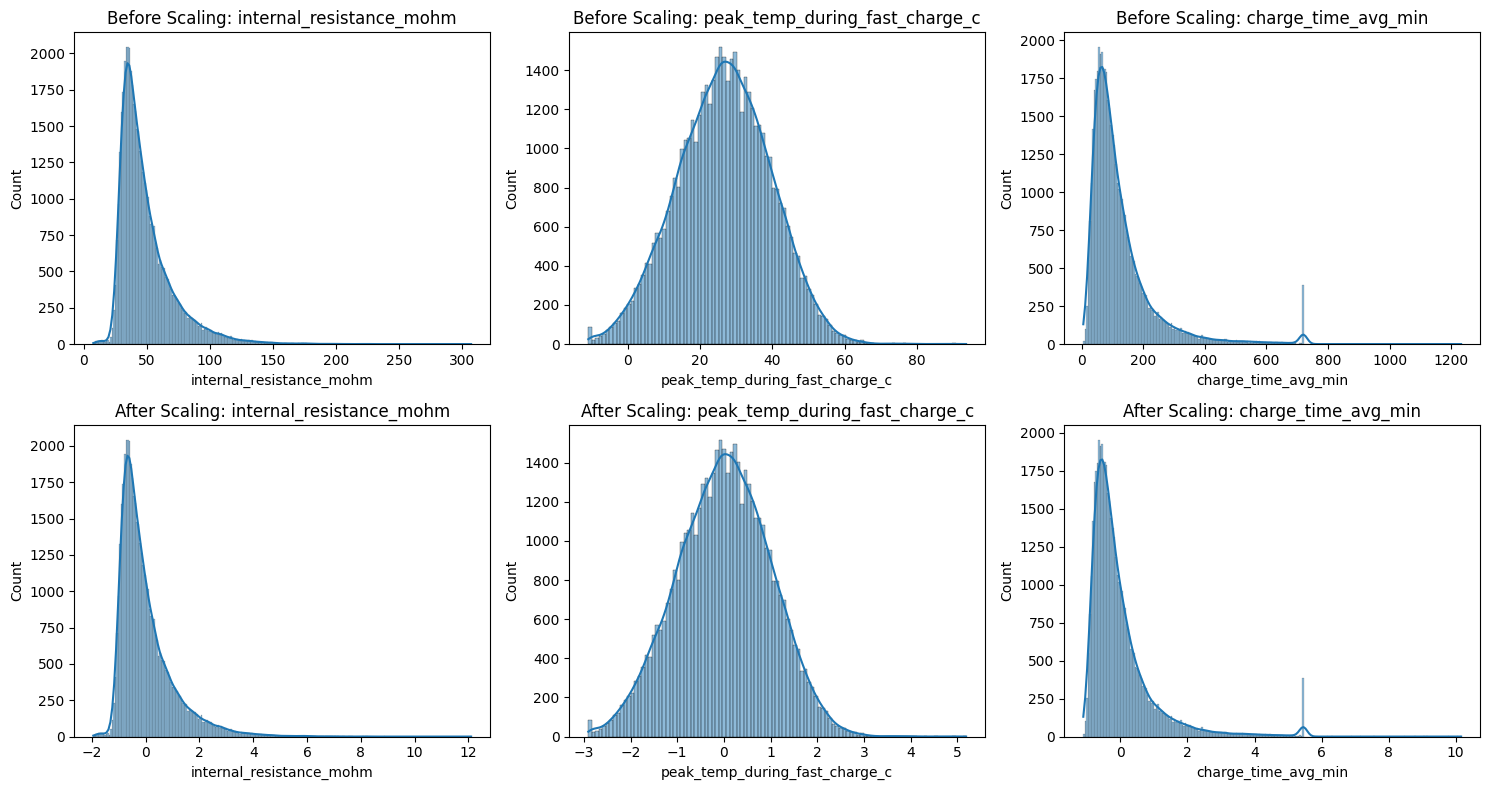

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(sensor_features):

    sns.histplot(data[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'Before Scaling: {col}')

    sns.histplot(processed_data[col], kde=True, ax=axes[1, i])
    axes[1, i].set_title(f'After Scaling: {col}')

plt.tight_layout()
plt.show()